# 09. Figure 2, tunable

The map and the alliance boxplots, on the revision's numbers but keeping the published
design. Everything adjustable is in the **Settings** cell.

Three files come out of this: `Fig2a_map`, `Fig2b_alliances` and the combined `Figure2_full`,
each as png, pdf and svg.

| setting | what it does |
|---|---|
| `OCEAN`, `LAND`, `BORDER` | base map colours |
| `ADI_BANDS`, `ADI_SIZES` | bubble size bands and their labels |
| `OSI_STOPS`, `OSI_BANDS` | the stance colour ramp, and whether it is banded or smooth |
| `LABEL_COUNTRIES` | which countries are annotated, and the arrow style |
| `BOX_COLORS` | one colour per alliance |

In [1]:
import sys, os
sys.path.insert(0, os.path.join(os.getcwd(), 'src'))  # the modules the notebooks import live in src/


In [2]:
import os, sys, warnings
warnings.filterwarnings('ignore')
sys.path.insert(0, '.')
import numpy as np, pandas as pd, geopandas as gpd
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, BoundaryNorm, Normalize
from matplotlib.lines import Line2D
from matplotlib.patches import FancyBboxPatch
import config as cfg, figures as fg, regress as rg

In [3]:
OUT = 'output/figures'
os.makedirs(OUT, exist_ok=True)

# Natural Earth 1:50m Admin 0 Countries. Public domain, no permission required
# (naturalearthdata.com/about/terms-of-use). Countries are matched on ISO3 rather than
# on name, because the spellings differ from the ones used elsewhere in the pipeline.
BASEMAP = 'assets/naturalearth/ne_50m_admin_0_countries.shp'

idx = pd.read_csv('output/indices_2022_by_country.csv', index_col=0)
world = gpd.read_file(BASEMAP)
world = world[world.geometry.notna()].copy()
world['iso'] = world.ISO_A3.where(world.ISO_A3 != '-99', world.ADM0_A3)

_cw = rg.crosswalk()
ISO3 = {c: _cw.get(c) for c in idx.index}
_missing = [c for c, v in ISO3.items() if v is None or v not in set(world.iso)]
print('countries with no polygon:', _missing or 'none')

ALLIANCES = fg.ALLIANCES          # the seven UNFCCC groups, as curated in figures.py

def rescale(v):
    v = np.asarray(v, float)
    lo, hi = np.nanmin(v), np.nanmax(v)
    return (v - lo) / (hi - lo)

idx['ADI_scaled'] = rescale(idx.ADI)
print(f'{len(idx)} countries')
print(f'ADI  raw {idx.ADI.min():.3f}-{idx.ADI.max():.3f}   rescaled mean {idx.ADI_scaled.mean():.3f}')
print(f'OSI  {idx.OSI.min():.3f}-{idx.OSI.max():.3f}   mean {idx.OSI.mean():.3f}')

countries with no polygon: none
100 countries
ADI  raw 0.013-0.290   rescaled mean 0.314
OSI  0.279-0.929   mean 0.725


## Settings

In [4]:
# ---- base map ------------------------------------------------------------------
OCEAN  = '#F9FAFC'     # the sea, i.e. the panel background
OCEAN_EDGE    = None   # a hex colour draws a frame round the map; None leaves it open
OCEAN_EDGE_LW = 0.8
FIG_BG = '#FFFFFF'     # the canvas outside the map: margins, legend box, boxplots
LAND   = '#FFFFFF'     # country fill
BORDER = '#CCCCCC'     # country outlines
BORDER_WIDTH = 0.3
MAP_XLIM, MAP_YLIM = (-180, 180), (-60, 85)

# ---- bubbles -------------------------------------------------------------------
# (upper bound, label, printed range). The last bound is np.inf.
ADI_BANDS = [(0.15, 'low',         '<0.15'),
             (0.25, 'medium-low',  '>=0.15, <0.25'),
             (0.55, 'medium-high', '>=0.25, <0.55'),
             (np.inf, 'high',      '>=0.55')]
ADI_SIZES = [20, 57, 200, 701]          # area ratios 1 : 1.92 : 4.31 : 12.52,
                                        # measured off the published legend circles
                                        # (diameters 13, 18, 27 and 46 px)
BUBBLE_SCALE = 1.0                      # multiplies all four sizes at once
BUBBLE_EDGE  = 'black'
BUBBLE_LW    = 0.1
BUBBLE_ALPHA = 0.88

# ---- stance colour ---------------------------------------------------------------
OSI_STOPS = ['#D22E76', '#DD4C82', '#F3899A', '#F0A3A2', '#E8B7A7',
             '#D4C7A3', '#B6C895', '#91B97C', '#76AE6D']   # sampled pixel by pixel
                                                           # from the published legend
# Band edges. The published bands were set on the earlier sample, where OSI averaged
# 0.61. On the rebuilt sample it averages 0.73, so those edges now put 93 of the 100
# countries in the top two bands. Run band_check() below to see the counts.
OSI_BANDS = [0.55, 0.65, 0.75, 0.85]    # the published edges
# OSI_BANDS = [0.65, 0.70, 0.76, 0.84]  # quintiles of the rebuilt sample, 20 per band
# OSI_BANDS = None                      # a smooth ramp instead of bands
OSI_BAND_NAMES = ['very low', 'low', 'medium', 'high', 'very high']

# ---- annotations -----------------------------------------------------------------
LABEL_COUNTRIES = ['Iceland', 'Ukraine', 'Japan', 'Jamaica', 'Dominican Republic', 'Serbia',
                   'Malaysia', 'Zambia', 'Mozambique', 'Australia', 'South Africa', 'New Zealand']
                   # the twelve countries named in the published Figure 2a
SHOW_LABELS = True           # False removes every country name from the map
LABEL_ALL      = False         # True labels all 100 countries, for inspection.
                               # Expect overlap; drop LABEL_FONTSIZE and set
                               # ARROWS = False to make it readable.
LABEL_FONTSIZE = 10
LABEL_FONT     = 'Times New Roman'
LABEL_OFFSET   = (14, 14)      # points, from the bubble
ARROWS         = True          # draw a curved arrow from the label to the bubble
ARROW_COLOR    = 'black'
ARROW_WIDTH    = 0.7

# ---- boxplots ---------------------------------------------------------------------
BOX_COLORS = ['#92AAB8',        # G77 & China
              '#A6BC97',        # SIDS
              '#C0938F',        # LDC
              '#D6CAAD',        # Arab Group
              '#C5B9D3',        # Umbrella Group
              '#A6968A',        # EIG
              '#9DBAC2']        # EU
BOX_ALPHA     = 1.0
BOX_WIDTH     = 0.6
BOX_EDGE      = '#333333'       # outline of the box
BOX_EDGE_LW   = 0.4
MEDIAN_COLOR  = '#444444'
MEDIAN_LW     = 1.1
WHISKER_COLOR = '#555555'       # whiskers, caps and the outlier rings
FLIER_SIZE    = 3
MEAN_LINE     = '#FF0000'       # the "total mean" rule, drawn over the boxes
MEAN_LINE_LW  = 1.2
MEAN_LABEL    = 'Total Mean'
SHOW_N        = True            # print (n = x) under each alliance, required by the journal

# ---- boxplot type ------------------------------------------------------------------
BOX_FONT         = 'DejaVu Sans'   # the face the published panels use
BOX_TEXT_COLOR   = '#262626'
BOX_TITLE_SIZE   = 13
BOX_YLABEL_SIZE  = 12
BOX_TICK_SIZE    = 10           # the numbers on the y axis
BOX_FONTSIZE     = 9            # the alliance names
BOX_LEGEND_SIZE  = 10
BOX_LEGEND_FRAME = True

# ---- boxplot frame -----------------------------------------------------------------
BOX_FRAME       = 'axes'        # 'full' boxes the panel in on all four sides;
                                # 'axes' keeps only the left and bottom spines
BOX_FRAME_LW    = 1.0
BOX_FRAME_COLOR = '#262626'

# ---- sizes -------------------------------------------------------------------------
MAP_FIGSIZE  = (16, 8)
BOX_FIGSIZE  = (5, 9)
FULL_FIGSIZE = (20, 10)
DPI = 300

## The map

In [5]:
def osi_cmap_norm():
    cmap = LinearSegmentedColormap.from_list('osi', OSI_STOPS)
    if OSI_BANDS:
        edges = [min(idx.OSI.min(), OSI_BANDS[0])] + list(OSI_BANDS) + [max(idx.OSI.max(), OSI_BANDS[-1])]
        colors = [cmap(x) for x in np.linspace(0, 1, len(edges) - 1)]
        cmap = mpl.colors.ListedColormap(colors)
        norm = BoundaryNorm(edges, cmap.N)
    else:
        norm = Normalize(idx.OSI.min(), idx.OSI.max())
    return cmap, norm


def adi_band(v):
    for i, (hi, _, _) in enumerate(ADI_BANDS):
        if v < hi:
            return i
    return len(ADI_BANDS) - 1


def draw_map(ax, panel_letter='a'):
    ax.set_facecolor(OCEAN)
    world.plot(ax=ax, color=LAND, edgecolor=BORDER, linewidth=BORDER_WIDTH, zorder=1)

    iso_to_name = {v: k for k, v in ISO3.items() if v}
    w = world[world.iso.isin(iso_to_name)].copy()
    w['c'] = w.iso.map(iso_to_name)
    w = w.dissolve(by='c')
    pt = w.geometry.representative_point()
    w['lon'], w['lat'] = pt.x, pt.y
    common = [c for c in idx.index if c in w.index]

    cmap, norm = osi_cmap_norm()
    sizes = [ADI_SIZES[adi_band(idx.ADI_scaled[c])] * BUBBLE_SCALE for c in common]
    ax.scatter(w.loc[common, 'lon'], w.loc[common, 'lat'], s=sizes,
               c=idx.loc[common, 'OSI'], cmap=cmap, norm=norm,
               edgecolor=BUBBLE_EDGE, linewidth=BUBBLE_LW, alpha=BUBBLE_ALPHA, zorder=5)

    _names = list(idx.index) if LABEL_ALL else LABEL_COUNTRIES
    for c in (_names if SHOW_LABELS else []):
        if c not in w.index:
            continue
        xy = (w.loc[c, 'lon'], w.loc[c, 'lat'])
        ax.annotate(c, xy, xytext=LABEL_OFFSET, textcoords='offset points',
                    fontsize=LABEL_FONTSIZE, fontweight='bold', fontfamily=LABEL_FONT,
                    zorder=6,
                    arrowprops=dict(arrowstyle='-|>', color=ARROW_COLOR,
                                    lw=ARROW_WIDTH, shrinkA=2, shrinkB=6,
                                    connectionstyle='arc3,rad=0.2') if ARROWS else None)
    ax.set_xlim(*MAP_XLIM); ax.set_ylim(*MAP_YLIM)
    # not ax.axis('off'): that hides the background patch and the sea colour with it.
    # Hide the ticks and the frame instead, and the patch stays.
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_facecolor(OCEAN)
    for s in ax.spines.values():
        if OCEAN_EDGE:
            s.set_visible(True); s.set_color(OCEAN_EDGE); s.set_linewidth(OCEAN_EDGE_LW)
        else:
            s.set_visible(False)
    if panel_letter:
        ax.text(0.004, 0.99, panel_letter, transform=ax.transAxes, ha='left', va='top',
                fontsize=15, fontweight='bold')
    return cmap, norm


def draw_legend(ax, cmap, norm):
    """The boxed key under the map, as in the published figure."""
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis('off')
    ax.add_patch(FancyBboxPatch((0.005, 0.03), 0.99, 0.94, boxstyle='round,pad=0.004',
                                fill=False, ec='black', lw=1.1, ls=(0, (4, 3))))
    ax.text(0.03, 0.80, 'Attention Distance Index (ADI)', fontsize=12,
            fontweight='bold', fontfamily=LABEL_FONT)
    for i, (s, (_, name, rng)) in enumerate(zip(ADI_SIZES, ADI_BANDS)):
        x = 0.05 + i * 0.10
        ax.scatter([x], [0.52], s=s * BUBBLE_SCALE, facecolor='none',
                   edgecolor=BUBBLE_EDGE, lw=0.9)
        ax.text(x, 0.30, name, ha='center', fontsize=9.5, fontfamily=LABEL_FONT)
        ax.text(x, 0.17, rng, ha='center', fontsize=9.5, fontfamily=LABEL_FONT)

    ax.text(0.53, 0.80, 'Online Stance Index (OSI)', fontsize=12,
            fontweight='bold', fontfamily=LABEL_FONT)
    x0, x1, y0, h = 0.53, 0.97, 0.50, 0.11
    n = cmap.N
    for i in range(n):
        ax.add_patch(plt.Rectangle((x0 + (x1 - x0) * i / n, y0), (x1 - x0) / n, h,
                                   facecolor=cmap(i), edgecolor='none'))
    ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, h, fill=False, ec='black', lw=0.6))
    if OSI_BANDS:
        for i, nm in enumerate(OSI_BAND_NAMES[:n]):
            xc = x0 + (x1 - x0) * (i + 0.5) / n
            ax.text(xc, 0.30, nm, ha='center', fontsize=9.5, fontfamily=LABEL_FONT)
            lo = '' if i == 0 else f'>={OSI_BANDS[i-1]}'
            hi = '' if i == n - 1 else f'<{OSI_BANDS[i]}'
            ax.text(xc, 0.17, (lo + (', ' if lo and hi else '') + hi), ha='center',
                    fontsize=9.5, fontfamily=LABEL_FONT)

def band_check(edges=None):
    """How many countries fall in each OSI band, for tuning OSI_BANDS."""
    e = edges if edges is not None else OSI_BANDS
    if not e:
        print('smooth ramp, no bands')
        return
    cuts = [-np.inf] + list(e) + [np.inf]
    n = np.histogram(idx.OSI, bins=cuts)[0]
    for i, k in enumerate(n):
        lo = '' if i == 0 else f'>={cuts[i]}'
        hi = '' if i == len(n) - 1 else f'<{cuts[i+1]}'
        nm = OSI_BAND_NAMES[i] if i < len(OSI_BAND_NAMES) else f'band {i+1}'
        print(f'  {nm:<10s} {lo:>7s} {hi:>7s}   {k:3d} countries')
    print(f'  quintiles of this sample: {list(idx.OSI.quantile([.2,.4,.6,.8]).round(2))}')


band_check()

  very low             <0.55     7 countries
  low         >=0.55   <0.65    14 countries
  medium      >=0.65   <0.75    36 countries
  high        >=0.75   <0.85    28 countries
  very high   >=0.85            15 countries
  quintiles of this sample: [0.65, 0.7, 0.76, 0.84]


## The alliance boxplots

In [6]:
def alliance_frame():
    rows = []
    for name, members in ALLIANCES.items():
        for c in members:
            if c in idx.index:
                rows.append({'alliance': name, 'country': c,
                             'ADI': idx.ADI_scaled[c], 'OSI': idx.OSI[c]})
    return pd.DataFrame(rows)


def draw_boxes(axes, letters=('b', 'c')):
    af = alliance_frame()
    order = list(ALLIANCES)
    n = {a: int((af.alliance == a).sum()) for a in order}
    for ax, col, name, total, L in [
            (axes[0], 'ADI', 'Attention Distance Index', idx.ADI_scaled.mean(), letters[0]),
            (axes[1], 'OSI', 'Online Stance Index',      idx.OSI.mean(),        letters[1])]:
        data = [af.loc[af.alliance == a, col].dropna().to_numpy() for a in order]
        bp = ax.boxplot(
            data, patch_artist=True, widths=BOX_WIDTH, showfliers=True,
            boxprops=dict(edgecolor=BOX_EDGE, linewidth=BOX_EDGE_LW),
            whiskerprops=dict(color=WHISKER_COLOR, linewidth=BOX_EDGE_LW),
            capprops=dict(color=WHISKER_COLOR, linewidth=BOX_EDGE_LW),
            medianprops=dict(color=MEDIAN_COLOR, linewidth=MEDIAN_LW),
            flierprops=dict(marker='o', markersize=FLIER_SIZE, markerfacecolor='none',
                            markeredgecolor=WHISKER_COLOR, markeredgewidth=0.7))
        for patch, c in zip(bp['boxes'], BOX_COLORS):
            patch.set_facecolor(c); patch.set_alpha(BOX_ALPHA)
        ax.axhline(total, color=MEAN_LINE, ls='--', lw=MEAN_LINE_LW,
                   label=MEAN_LABEL, zorder=5)
        ax.set_xticks(range(1, len(order) + 1))
        labs = [f'{a}\n(n = {n[a]})' if SHOW_N else a for a in order]
        ax.set_xticklabels(labs, rotation=90, fontsize=BOX_FONTSIZE, fontweight='bold',
                           fontfamily=BOX_FONT, color=BOX_TEXT_COLOR)
        ax.tick_params(axis='y', labelsize=BOX_TICK_SIZE, colors=BOX_TEXT_COLOR)
        for t in ax.get_yticklabels():
            t.set_fontfamily(BOX_FONT)
        ax.set_ylabel(col, fontsize=BOX_YLABEL_SIZE, fontweight='bold',
                      fontfamily=BOX_FONT, color=BOX_TEXT_COLOR)
        ax.set_title(f'({L}) {name}', fontsize=BOX_TITLE_SIZE, fontweight='bold',
                     fontfamily=BOX_FONT, color=BOX_TEXT_COLOR)
        ax.set_ylim(0, 1)
        for side, sp in ax.spines.items():
            sp.set_visible(BOX_FRAME == 'full' or side in ('left', 'bottom'))
            sp.set_linewidth(BOX_FRAME_LW)
            sp.set_color(BOX_FRAME_COLOR)
        leg = ax.legend(frameon=BOX_LEGEND_FRAME, fontsize=BOX_LEGEND_SIZE)
        for t in leg.get_texts():
            t.set_fontfamily(BOX_FONT); t.set_color(BOX_TEXT_COLOR)
    return n


## The three outputs

saved output/figures/Fig2a_map.{png,pdf,svg}


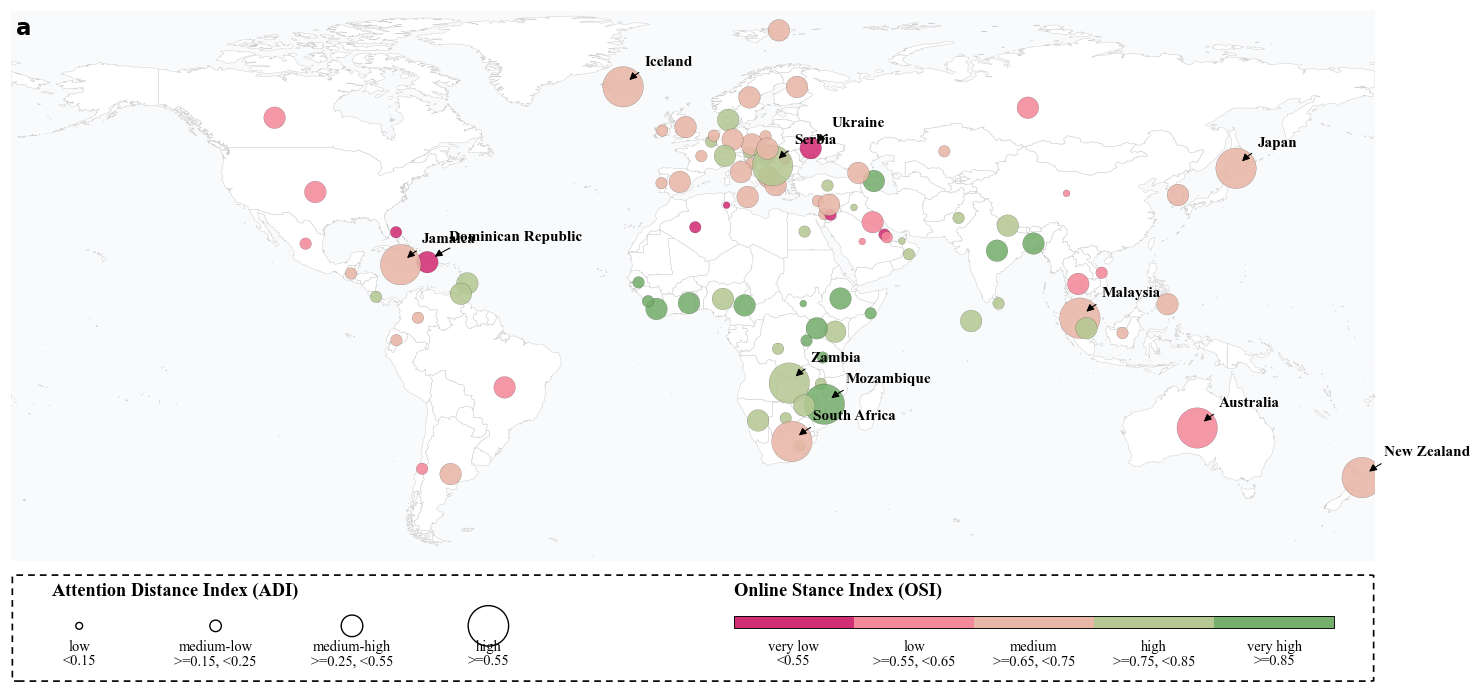

In [7]:
def save(fig, name):
    for ext in ('png', 'pdf', 'svg'):
        fig.savefig(os.path.join(OUT, f'{name}.{ext}'), dpi=DPI,
                    bbox_inches='tight', facecolor=FIG_BG)
    print('saved', os.path.join(OUT, name) + '.{png,pdf,svg}')


# map on its own, with the key beneath it
fig = plt.figure(figsize=MAP_FIGSIZE, dpi=110)
gs = fig.add_gridspec(2, 1, height_ratios=[5, 1], hspace=0.02)
cmap, norm = draw_map(fig.add_subplot(gs[0]))
draw_legend(fig.add_subplot(gs[1]), cmap, norm)
save(fig, 'Fig2a_map'); plt.show()

saved output/figures/Fig2b_alliances.{png,pdf,svg}


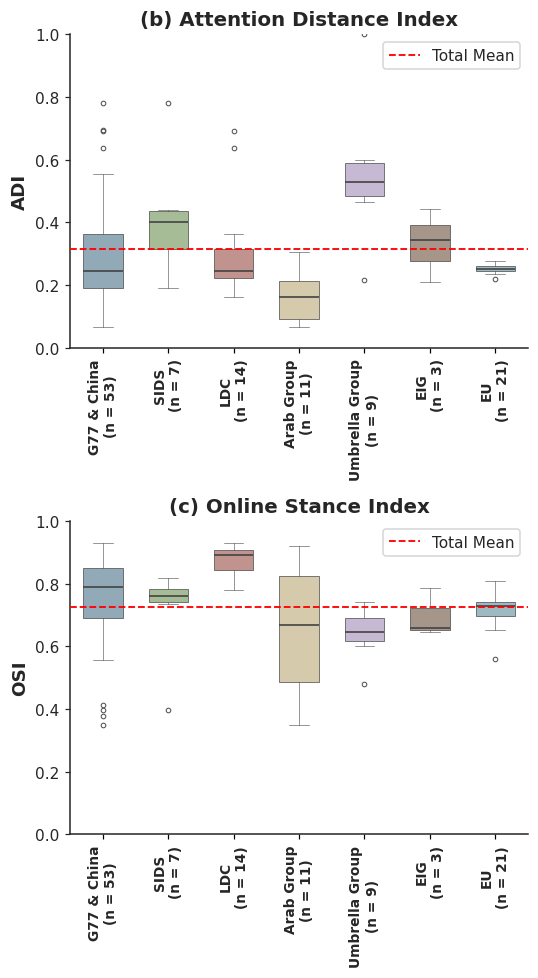

{'G77 & China': 53, 'SIDS': 7, 'LDC': 14, 'Arab Group': 11, 'Umbrella Group': 9, 'EIG': 3, 'EU': 21}


In [8]:
fig, axes = plt.subplots(2, 1, figsize=BOX_FIGSIZE, dpi=110)
n = draw_boxes(axes)
plt.tight_layout()
save(fig, 'Fig2b_alliances'); plt.show()
print({k: v for k, v in n.items()})

saved output/figures/Figure2_full.{png,pdf,svg}


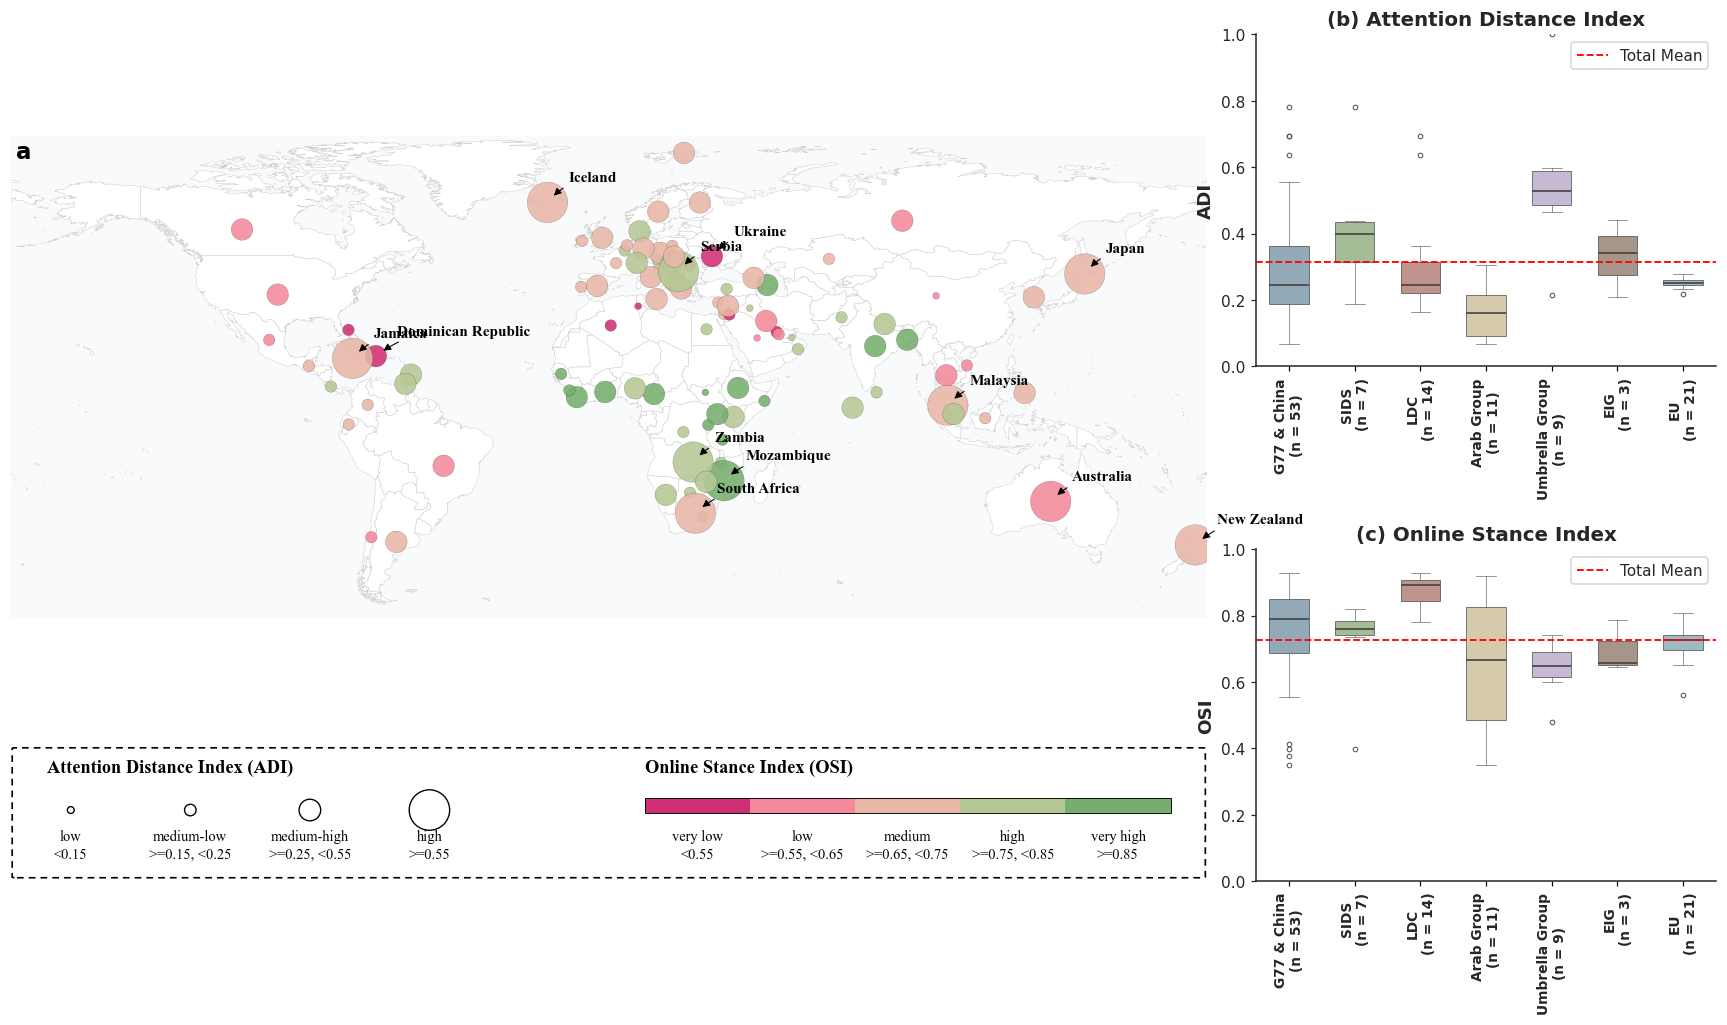

In [9]:
# the published layout: map and key on the left, the two boxplots stacked on the right
fig = plt.figure(figsize=FULL_FIGSIZE, dpi=110)
gs = fig.add_gridspec(2, 2, width_ratios=[2.6, 1], height_ratios=[5, 1],
                      wspace=0.06, hspace=0.06)
cmap, norm = draw_map(fig.add_subplot(gs[0, 0]))
draw_legend(fig.add_subplot(gs[1, 0]), cmap, norm)
inner = gs[:, 1].subgridspec(2, 1, hspace=0.55)
draw_boxes([fig.add_subplot(inner[0]), fig.add_subplot(inner[1])])
save(fig, 'Figure2_full'); plt.show()

## The numbers behind the panels

In [10]:
af = alliance_frame()
t = af.groupby('alliance').agg(countries=('country', 'size'),
                               ADI_mean=('ADI', 'mean'), ADI_median=('ADI', 'median'),
                               OSI_mean=('OSI', 'mean'), OSI_median=('OSI', 'median'))
t = t.reindex(list(ALLIANCES))
t.to_csv(os.path.join(OUT, 'Fig2_values.csv'))
print('total mean  ADI', round(idx.ADI_scaled.mean(), 4), '  OSI', round(idx.OSI.mean(), 4))
t.round(3)

total mean  ADI 0.3143   OSI 0.725


,countries,ADI_mean,ADI_median,OSI_mean,OSI_median
alliance,,,,,
G77 & China,53,0.293,0.245,0.751,0.790
SIDS,7,0.410,0.400,0.718,0.759
LDC,14,0.307,0.244,0.875,0.891
Arab Group,11,0.164,0.162,0.649,0.667
Umbrella Group,9,0.547,0.529,0.639,0.647
EIG,3,0.330,0.342,0.696,0.658
EU,21,0.252,0.252,0.720,0.727


## An interactive copy, for checking which country is which

The printed map stays unlabelled. This writes a standalone HTML file instead, where
hovering over a bubble names the country and gives its indices. Open
`output/figures/Fig2_interactive.html` in any browser. It uses the same colours, bands and
sizes as the Settings above, so it is the same map, just readable.

In [11]:
import plotly.graph_objects as go

HOVER_BG   = 'white'
HOVER_SIZE = 12
PROJECTION = 'natural earth'      # or 'equirectangular', 'robinson', 'miller'


def interactive_map(save='Fig2_interactive'):
    iso_to_name = {v: k for k, v in ISO3.items() if v}
    w = world[world.iso.isin(iso_to_name)].copy()
    w['c'] = w.iso.map(iso_to_name)
    w = w.dissolve(by='c')
    pt = w.geometry.representative_point()
    w['lon'], w['lat'] = pt.x, pt.y
    common = [c for c in idx.index if c in w.index]

    cmap, _ = osi_cmap_norm()
    band_of = lambda v: min(int(np.searchsorted(OSI_BANDS, v, side='right')), cmap.N - 1) \
        if OSI_BANDS else None

    # which alliances each country belongs to, so the tooltip can say so
    member = {c: [] for c in common}
    for name, members in ALLIANCES.items():
        for c in members:
            if c in member:
                member[c].append(name)

    fig = go.Figure()
    groups = range(cmap.N) if OSI_BANDS else [0]
    for b in groups:
        sel = [c for c in common if (band_of(idx.OSI[c]) == b if OSI_BANDS else True)]
        if not sel:
            continue
        col = mpl.colors.to_hex(cmap(b)) if OSI_BANDS else mpl.colors.to_hex(cmap(0.5))
        if OSI_BANDS:
            lo = '' if b == 0 else f'{OSI_BANDS[b-1]}'
            hi = '' if b == cmap.N - 1 else f'{OSI_BANDS[b]}'
            nm = f'{lo}–{hi}'.strip('–') if (lo or hi) else 'all'
            nm = (f'< {hi}' if not lo else f'≥ {lo}' if not hi else f'{lo} – {hi}')
        else:
            nm = 'OSI'
        fig.add_trace(go.Scattergeo(
            lon=[w.loc[c, 'lon'] for c in sel],
            lat=[w.loc[c, 'lat'] for c in sel],
            text=[c for c in sel],
            name=nm,
            customdata=[[round(idx.ADI[c], 3), round(idx.ADI_scaled[c], 3),
                         round(idx.OSI[c], 3), int(idx.n_posts[c]),
                         ', '.join(member[c]) or '—'] for c in sel],
            hovertemplate=('<b>%{text}</b><br>'
                           'ADI %{customdata[0]} (rescaled %{customdata[1]})<br>'
                           'OSI %{customdata[2]}<br>'
                           'posts %{customdata[3]:,}<br>'
                           'alliance %{customdata[4]}<extra></extra>'),
            mode='markers',
            marker=dict(
                size=[np.sqrt(ADI_SIZES[adi_band(idx.ADI_scaled[c])] * BUBBLE_SCALE) * 1.9
                      for c in sel],
                color=col, opacity=BUBBLE_ALPHA,
                line=dict(color=BUBBLE_EDGE, width=BUBBLE_LW * 2)),
        ))

    fig.update_geos(projection_type=PROJECTION, showcountries=True,
                    countrycolor=BORDER, countrywidth=0.4,
                    showland=True, landcolor=LAND,
                    showocean=True, oceancolor=OCEAN,
                    showframe=False, showcoastlines=False,
                    lataxis_range=list(MAP_YLIM), lonaxis_range=list(MAP_XLIM))
    fig.update_layout(
        margin=dict(l=0, r=0, t=36, b=0), height=720,
        paper_bgcolor=FIG_BG, plot_bgcolor=FIG_BG,
        title=dict(text='Communicative distance by country. '
                        'Bubble size is ADI, colour is OSI. Hover for details.',
                   x=0.01, font=dict(size=13)),
        legend=dict(title='OSI band', orientation='v', x=0.01, y=0.35,
                    bgcolor='rgba(255,255,255,0.75)'),
        hoverlabel=dict(bgcolor=HOVER_BG, font_size=HOVER_SIZE),
    )
    if save:
        path = os.path.join(OUT, f'{save}.html')
        fig.write_html(path, include_plotlyjs='cdn')
        print('saved', path)
    return fig


interactive_map()

saved output/figures/Fig2_interactive.html
